In [2]:
import sys
sys.path.append("../")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit.quantum_info import Statevector, SparsePauliOp
from qitp.engine.unitary_approximation import UnitaryApproximation
from qitp.engine.propagation import QITEPropagation
from qitp.engine.cqite_run import run_qite
from qitp.engine.prepare_state import constraint_rotation, prepare_state
from qitp.simulation.backend import SimulatorBackend

In [4]:
from qitp.ansatz.pauli_basis import (
    PauliBasis
)
from qitp.ansatz.commutator_basis import (
    CommutatorBasis
)

In [5]:
from qiskit.quantum_info import SparsePauliOp

h = 1.0
J = 1.0

H = SparsePauliOp(
    [
        "XII",
        "IXI",
        "IIX",
        "ZZI",
        "ZIZ",
        "IZZ",
    ],
    coeffs=[h, h, h, J, J, J]
)

In [6]:
Mz = constraints = [
    SparsePauliOp(["ZII"], coeffs=[1.0]),
    SparsePauliOp(["IZI"], coeffs=[1.0]),
    SparsePauliOp(["IIZ"], coeffs=[1.0]),
]

Identity = SparsePauliOp(["III"],coeffs=[1.0])

In [7]:
#seeds = [
#    SparsePauliOp("ZII"),
#    SparsePauliOp("IZI"),
#    SparsePauliOp("IIZ"),
#    SparsePauliOp("XII"),
#    SparsePauliOp("IXI"),
#    SparsePauliOp("IIX")
#]

In [9]:
#basis = CommutatorBasis.from_seed(hamiltonian=H, seeds=seeds, depth=1)

In [64]:
#basis.paulis

In [66]:
dt=1e-1
nsteps=20
target=0.0

energies=[]
fidelities=[]
errors=[]
magnetizations=[]

In [68]:
rotations = []

for constraint in Mz:

    rotations.append(
        constraint_rotation(
            constraint,
            target
        )
    )

In [70]:
circuit = prepare_state(
    3,
    rotations
)

In [72]:
circuit = circuit.decompose()

In [76]:
basis = CommutatorBasis.from_rotations(hamiltonian=H, rotations=rotations, depth=2)

In [78]:
basis.paulis

[SparsePauliOp(['YII'],
               coeffs=[-1.+0.j]),
 SparsePauliOp(['IYI'],
               coeffs=[-1.+0.j]),
 SparsePauliOp(['IIY'],
               coeffs=[-1.+0.j]),
 SparsePauliOp(['ZII', 'XZI', 'XIZ'],
               coeffs=[-2.+0.j,  2.+0.j,  2.+0.j]),
 SparsePauliOp(['IZI', 'ZXI', 'IXZ'],
               coeffs=[-2.+0.j,  2.+0.j,  2.+0.j]),
 SparsePauliOp(['IIZ', 'ZIX', 'IZX'],
               coeffs=[-2.+0.j,  2.+0.j,  2.+0.j]),
 SparsePauliOp(['YII', 'XYI', 'XIY', 'YZZ'],
               coeffs=[12.+0.j, -4.+0.j, -4.+0.j,  8.+0.j]),
 SparsePauliOp(['YXI', 'IYI', 'IXY', 'ZYZ'],
               coeffs=[-4.+0.j, 12.+0.j, -4.+0.j,  8.+0.j]),
 SparsePauliOp(['YIX', 'IYX', 'IIY', 'ZZY'],
               coeffs=[-4.+0.j, -4.+0.j, 12.+0.j,  8.+0.j])]

In [84]:
approx = UnitaryApproximation(basis)

backend = SimulatorBackend()

prop = QITEPropagation(
    H,
    approx,
    backend
)

prop.constraints = [
    Identity]
prop.constraints.extend(Mz)

In [86]:
results = run_qite(
    prop,
    circuit,
    H,
    Mz,
    dt,
    nsteps
)

energies = results["energies"]
magnetizations = [np.sum(m) for m in results["magnetizations"]]

In [88]:
print(np.round(energies[-1],3))

-2.2


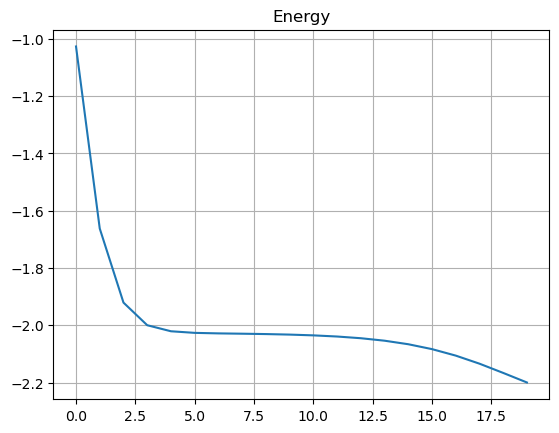

In [90]:
plt.plot(energies); plt.title('Energy'); plt.grid(); plt.show()

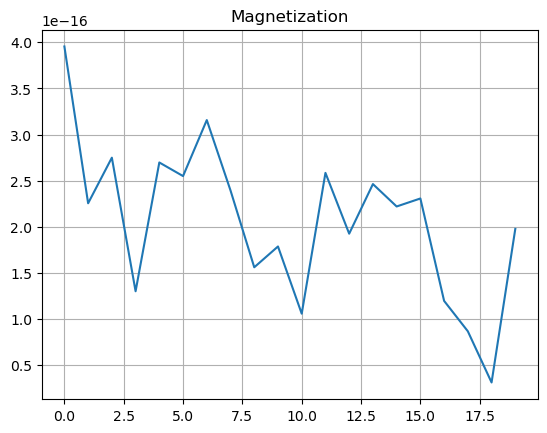

In [92]:
plt.plot(magnetizations); plt.title("Magnetization"); plt.grid(); plt.show()

In [364]:
evals = np.linalg.eigvalsh(
    H.to_matrix()
)

print("Exact spectrum")

print(np.round(evals,2))

Exact spectrum
[-3.46 -2.   -2.   -0.   -0.    0.    3.46  4.  ]
